# Spike train statistics
Poisson neurons: firing rates, ISIs, CV, binning and population bursts.

## 1. Simulate Poisson neurons

**Model.** Each neuron is a *homogeneous Poisson process*: it fires at random with a constant average rate $\lambda$ (spikes/s). The constant rate is the simplest assumption. It gives a clean baseline to compare real neurons against, since real neurons change their rate and burst.

**Inter-spike intervals (ISIs).** The ISI is the time between two consecutive spikes of the same neuron. If the neuron has the same small chance of firing at every instant and no memory of its last spike, the probability of waiting longer than $t$ without a spike is

$$P(\text{ISI} > t) = e^{-\lambda t}$$

so the ISIs follow an **exponential distribution**, $p(t) = \lambda e^{-\lambda t}$, with mean $1/\lambda$.

**Simulation.** For each neuron, we draw ISIs from this distribution and add them up (cumulative sum) to get spike times, keeping those inside the 60 s recording.

In [129]:
import numpy as np # numerical arrays and maths

rng = np.random.default_rng(42) # random generator with a fixed seed, so results are reproducible
T = 60.0 # recording length in seconds
rates = [2, 4, 6, 8, 10] # firing rate of each neuron in Hz

print(f"Recording length: {T} s") # show the settings
print(f"Rates (Hz): {rates}\n") # \n adds an empty line

spikes = [] # will hold one array of spike times per neuron
for r in rates: # loop over the 5 neurons
    n_spk = rng.poisson(r * T) # draw how many spikes the neuron fires in T seconds
    print(f"--- Neuron at {r} Hz ---")
    print(f"expected spikes (r*T): {r*T:.0f}, drawn: {n_spk}") # compare the expected and the random count

    t = np.sort(rng.uniform(0, T, n_spk)) # draw n_spk random spike times in [0, T] (they come out unordered), then sort them into time order, as in real recordings
    print(f"first 5 spike times (s): {np.round(t[:5], 2)}") # peek at the start of the spike train
    print(f"last spike time (s): {t[-1]:.2f}") # should be just under 60 s

    spikes.append(t) # store this neuron's spike times
    print(f"first 10 spike times (s): {np.round(t[:10], 2)}\n") # t[:10] = only the first 10 values

print("spikes per neuron:", [len(s) for s in spikes]) # final count per neuron

Recording length: 60.0 s
Rates (Hz): [2, 4, 6, 8, 10]

--- Neuron at 2 Hz ---
expected spikes (r*T): 120, drawn: 129
first 5 spike times (s): [0.44 1.36 1.85 2.5  2.63]
last spike time (s): 58.54
first 10 spike times (s): [0.44 1.36 1.85 2.5  2.63 3.5  3.83 5.07 5.26 5.4 ]

--- Neuron at 4 Hz ---
expected spikes (r*T): 240, drawn: 268
first 5 spike times (s): [0.74 0.84 1.07 1.27 1.3 ]
last spike time (s): 59.54
first 10 spike times (s): [0.74 0.84 1.07 1.27 1.3  1.37 1.49 2.24 2.61 2.69]

--- Neuron at 6 Hz ---
expected spikes (r*T): 360, drawn: 392
first 5 spike times (s): [0.07 0.1  0.27 0.28 0.33]
last spike time (s): 59.95
first 10 spike times (s): [0.07 0.1  0.27 0.28 0.33 0.44 0.56 0.64 0.88 1.06]

--- Neuron at 8 Hz ---
expected spikes (r*T): 480, drawn: 470
first 5 spike times (s): [0.03 0.06 0.14 0.24 0.45]
last spike time (s): 59.97
first 10 spike times (s): [0.03 0.06 0.14 0.24 0.45 0.75 0.99 1.09 1.19 1.39]

--- Neuron at 10 Hz ---
expected spikes (r*T): 600, drawn: 599
fi

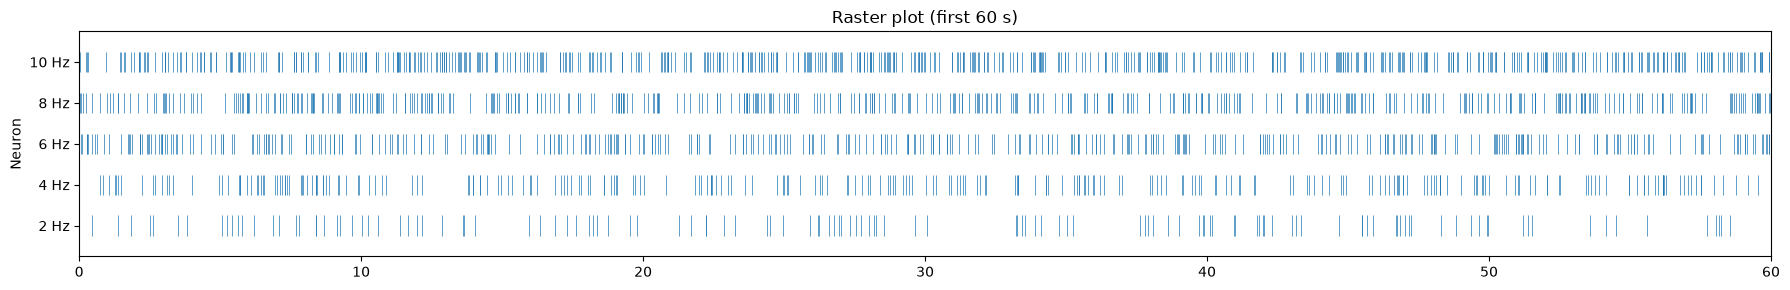

In [149]:
import matplotlib.pyplot as plt # plotting library

zoom_s = 60 # how many seconds to show; set to 10 for a close-up
fig, ax = plt.subplots(figsize=(18, 3)) # one wide plot
ax.eventplot(spikes, lineoffsets=range(len(rates)), # one row per neuron, one tick per spike
             linelengths=0.5, linewidths=0.5)
ax.set_yticks(range(len(rates))) # one y-tick per neuron
ax.set_yticklabels([f"{r} Hz" for r in rates]) # label each row with its rate
zoom = min(zoom_s, T) # never more than the recording
ax.set_xlim(0, zoom) # show from 0 to the chosen zoom
ax.set_ylabel("Neuron")
ax.set_title(f"Raster plot (first {zoom:g} s)") # title follows the zoom; :g drops the useless ".0"
plt.tight_layout() # avoid overlapping labels
plt.show()

## 2. Firing rates

The firing rate is the number of spikes divided by the recording time:

$$\text{rate} = \frac{N_\text{spikes}}{T}$$

Because the spike count is random (Poisson), the measured rate (the neuron's average rate over a finite recording) fluctuates around the true rate (its average rate over an infinitely long time). The true rate can never be observed directly, so we report the measured rate together with its uncertainty.

**How big is the uncertainty?** For a Poisson distribution with mean $\mu$, the variance equals the mean, so the standard deviation (SD) is $\sqrt{\mu}$. The expected spike count is $\mu = \lambda T$, so:

$$\text{SD(count)} = \sqrt{\lambda T} \qquad \text{typical relative error} = \frac{\sqrt{\lambda T}}{\lambda T} = \frac{1}{\sqrt{\lambda T}}$$

Example: a 2 Hz neuron over 60 s has 120 expected spikes, SD ≈ 11 spikes, so a typical relative error of ±9.1%. The error is larger for slow neurons and short recordings.

**Three kinds of error:**

| Error | Formula | Question it answers | Needs the true rate? |
|---|---|---|---|
| Typical error | $1/\sqrt{\lambda T}$ | How big is the error usually? (theory) | Yes |
| Relative error | $(\text{measured} - \lambda)/\lambda$ | How wrong was *this* measurement? | Yes |
| Estimated error | $1/\sqrt{N_\text{spikes}}$ | Same question, estimated from the data | No |

With real data only the estimated error is available, so a rate is reported as measured ± estimated error (e.g. 2.15 Hz ± 8.8%). In a simulation we know $\lambda$ and can check all three.

**Fano factor.** Cut the recording into windows (e.g. 1 s), count the spikes in each window, and compare how much the counts vary with their average:

$$F = \frac{\text{Var(count)}}{\text{mean(count)}} \qquad \text{Var} = \text{average of the squared distances from the mean}$$

Squaring makes all distances positive and gives large jumps (bursts) a big weight.

Example with a mean of 2 spikes per window:
- Poisson-like counts 2, 1, 3, 2, 0, 4: squared distances 0, 1, 1, 0, 4, 4, so Var = 1.67 and $F \approx 0.8$ (close to 1).
- Bursty counts 0, 0, 8, 0, 2: squared distances 4, 4, 36, 4, 0, so Var = 9.6 and $F = 4.8$.

For a Poisson neuron $F = 1$ (variance = mean). $F > 1$ means burstier than random, $F < 1$ more regular. It is the count-based counterpart of the CV, which does the same for ISIs.

In [131]:
for r, s in zip(rates, spikes): # pair each true rate with its spike times
    n = len(s) # number of spikes of this neuron
    measured = n / T # spikes / seconds = rate in Hz
    err = 100 * (measured - r) / r # relative error: how far off we are, in % of the true rate (simulation only)
    typical = 100 / np.sqrt(r * T) # typical error from theory: 1/√(true count), in % (simulation only)
    estimated = 100 / np.sqrt(n) # estimated error from the data: 1/√(measured count), in % (real data too)
    print(f"true rate {r:>2} Hz | typical error ±{typical:.1f} % | "
          f"spikes {n:>3} | measured rate {measured:5.2f} Hz | relative error {err:+5.1f} % | "
          f"estimated error ±{estimated:.1f} %")

true rate  2 Hz | typical error ±9.1 % | spikes 129 | measured rate  2.15 Hz | relative error  +7.5 % | estimated error ±8.8 %
true rate  4 Hz | typical error ±6.5 % | spikes 268 | measured rate  4.47 Hz | relative error +11.7 % | estimated error ±6.1 %
true rate  6 Hz | typical error ±5.3 % | spikes 392 | measured rate  6.53 Hz | relative error  +8.9 % | estimated error ±5.1 %
true rate  8 Hz | typical error ±4.6 % | spikes 470 | measured rate  7.83 Hz | relative error  -2.1 % | estimated error ±4.6 %
true rate 10 Hz | typical error ±4.1 % | spikes 599 | measured rate  9.98 Hz | relative error  -0.2 % | estimated error ±4.1 %


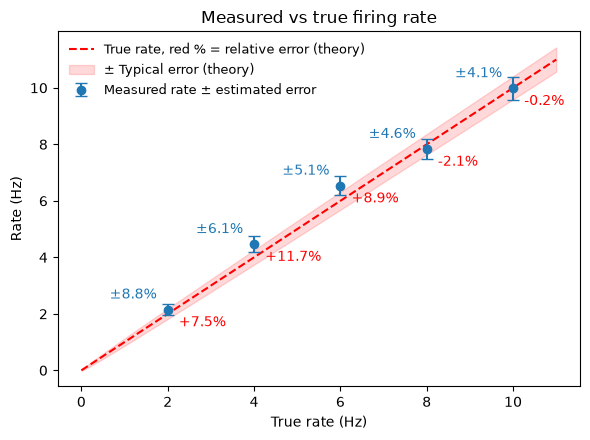

In [132]:
measured = [len(s) / T for s in spikes] # measured rate of each neuron (Hz)
counts = [len(s) for s in spikes] # spike count of each neuron
meas_err = [np.sqrt(n) / T for n in counts] # estimated error from the data itself: √(spike count) / T, in Hz
rel_err = [100 * (m - r) / r for m, r in zip(measured, rates)] # relative error of each neuron (%), needs the true rate

x = np.linspace(0, max(rates) * 1.1, 200) # 200 true rates from 0 to 10% above the fastest neuron, for a smooth line and band
band = np.sqrt(x * T) / T # typical error in Hz at each true rate: SD of the count / T

fig, ax = plt.subplots(figsize=(6, 4.5)) # one plot, a bit larger so all labels fit

# Simulation only (unknown in real data): red
ax.plot(x, x, "--", color="red", label="True rate, red % = relative error (theory)") # where a perfect measurement would land
ax.fill_between(x, x - band, x + band, color="red", alpha=0.15, # shaded band = true rate ± typical error
                label="± Typical error (theory)")
for r, m, e in zip(rates, measured, rel_err): # relative error: how wrong this measurement actually is
    ax.annotate(f"{e:+.1f}%", (r, m), textcoords="offset points", xytext=(8, -12), # below-right of the dot
                fontsize=10, color="red")

# Available in real data: blue
ax.errorbar(rates, measured, yerr=meas_err, fmt="o", capsize=4, color="tab:blue", # dots with vertical error bars
            label="Measured rate ± estimated error")
for r, m, n in zip(rates, measured, counts): # precision: how uncertain the measurement is, 1/√(spikes)
    ax.annotate(f"±{100 / np.sqrt(n):.1f}%", (r, m), textcoords="offset points", xytext=(-8, 8), # above-left of the dot
                ha="right", fontsize=10, color="tab:blue")

ax.set_xlabel("True rate (Hz)")
ax.set_ylabel("Rate (Hz)")
ax.set_title("Measured vs true firing rate")
ax.legend(frameon=False, fontsize=9, loc="upper left") # legend without a box, in the empty top-left corner
plt.tight_layout() # avoid overlapping labels
plt.show()

## 3. Inter-spike intervals (ISIs) and coefficient of variation (CV)

The ISI is the waiting time between consecutive spikes: $\text{ISI}_i = t_{i+1} - t_i$. This only makes sense if spike times are sorted; otherwise "the next spike" is not defined and differences can be negative.

For a Poisson neuron the ISIs are exponential with mean $1/\lambda$: slow neurons wait longer between spikes.

The **coefficient of variation** measures how irregular the waiting times are, independently of the rate:

$$\text{CV} = \frac{\text{SD(ISI)}}{\text{mean(ISI)}}$$

- CV = 0: perfectly regular (a clock).
- CV = 1: Poisson (exponential ISIs have SD = mean), poisson neurons with exponential waits that are mostly short and sometimes long. 
- CV > 1: bursty (short ISIs inside bursts, long silences between them), typical of cultured networks.

In [133]:
s = spikes[0] # first neuron (the slowest, since rates are sorted)
print(f"Neuron at {rates[0]} Hz") # its true rate, read from the settings
print("first 5 spike times (s):", np.round(s[:5], 2)) # sorted spike times
isi = np.diff(s) # each spike time minus the previous one
print("first 4 ISIs (s):       ", np.round(isi[:4], 2)) # real waiting times between spikes
print(f"smallest ISI: {isi.min():.4f} s (never negative)\n") # proof that all waits are positive

shuffled = np.random.default_rng(1).permutation(s) # same spikes in random order (own seed, so it's reproducible)
print("same spikes, NOT sorted:", np.round(shuffled[:5], 2))
bad = np.diff(shuffled) # 'intervals' between neighbours in the wrong order
print("'ISIs' from unsorted:   ", np.round(bad[:4], 2))
print(f"negative 'ISIs': {np.sum(bad < 0)} of {len(bad)}") # impossible negative waiting times

Neuron at 2 Hz
first 5 spike times (s): [0.44 1.36 1.85 2.5  2.63]
first 4 ISIs (s):        [0.92 0.49 0.65 0.13]
smallest ISI: 0.0027 s (never negative)

same spikes, NOT sorted: [41.78 19.55 42.31 10.24 45.67]
'ISIs' from unsorted:    [-22.23  22.76 -32.07  35.43]
negative 'ISIs': 65 of 128


In [134]:
isi = np.diff(spikes[0]) # ISIs of the first neuron
print(f"type(isi): {type(isi)}") # what kind of object it is: a NumPy array
print(f"len(spikes[0]): {len(spikes[0])}, len(isi): {len(isi)}") # always one fewer ISI than spikes
print(f"first 5 ISIs (s): {np.round(isi[:5], 2)}\n") # a few example values, in seconds

for r, s in zip(rates, spikes): # pair each true rate with its spike times
    isi = np.diff(s) # ISIs of this neuron
    m = isi.mean() # mean ISI, should be about 1/rate
    sd = isi.std() # spread of the ISIs, should also be about 1/rate
    cv = sd / m # coefficient of variation, should be about 1
    print(f"true rate {r:>2} Hz | expected mean ISI and SD {1000/r:4.0f} ms, CV 1 | "
          f"measured mean ISI {m*1000:4.0f} ms | measured SD {sd*1000:4.0f} ms | CV {cv:.2f}")

type(isi): <class 'numpy.ndarray'>
len(spikes[0]): 129, len(isi): 128
first 5 ISIs (s): [0.92 0.49 0.65 0.13 0.87]

true rate  2 Hz | expected mean ISI and SD  500 ms, CV 1 | measured mean ISI  454 ms | measured SD  498 ms | CV 1.10
true rate  4 Hz | expected mean ISI and SD  250 ms, CV 1 | measured mean ISI  220 ms | measured SD  236 ms | CV 1.07
true rate  6 Hz | expected mean ISI and SD  167 ms, CV 1 | measured mean ISI  153 ms | measured SD  141 ms | CV 0.92
true rate  8 Hz | expected mean ISI and SD  125 ms, CV 1 | measured mean ISI  128 ms | measured SD  129 ms | CV 1.01
true rate 10 Hz | expected mean ISI and SD  100 ms, CV 1 | measured mean ISI  100 ms | measured SD   99 ms | CV 0.98


### ISI distributions: slowest vs fastest neuron

The following charts show histograms of the measured ISIs (blue) for the slowest and fastest neuron, on the same x-axis and with the same bins, compared with the exponential distribution predicted for a Poisson neuron (red, $p(t) = \lambda e^{-\lambda t}$).

The height of the curve and bars is a *probability density*: "probability per second". To get a probability, multiply height × width:
- In the 2 Hz chart, the red curve's height at 0.1 s is about 1.6. The chance that an ISI falls between 0.10 and 0.11 s is $1.6 \times 0.01 = 1.6\%$.
- Each blue bar's height × its width is the fraction of ISIs in that bar; all bars together add up to 1 (100% of ISIs).

That is why the 10 Hz chart reaches 10 on the y-axis: its ISIs are squeezed into short times, and a narrow shape must be tall to keep a total area of 1.

**Message:** the measured ISIs follow the exponential prediction at any rate: many short waits and few long ones. A faster neuron only compresses the time scale, since its mean ISI is $1/\lambda$.

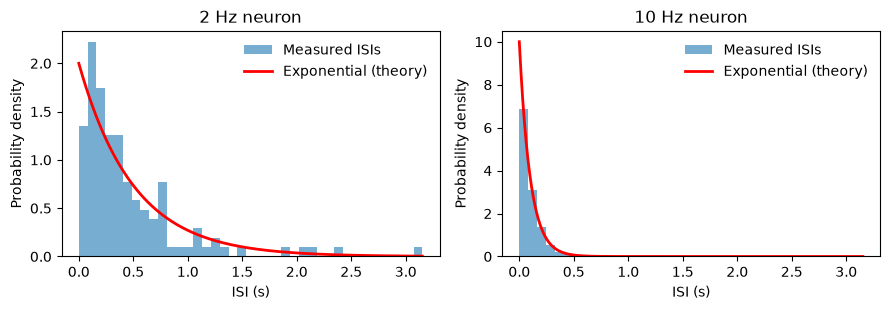

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharex=True) # two plots side by side, same x-axis
idxs = [0, len(rates) - 1] # slowest and fastest neuron
isi_max = max(np.diff(spikes[i]).max() for i in idxs) # longest ISI of the two, sets the common x-range
bins = np.linspace(0, isi_max, 40) # the same 40 bins for both histograms, for a fair comparison
x = np.linspace(0, isi_max, 200) # 200 points along the common x-range, for a smooth theory curve

for ax, idx in zip(axes, idxs): # one plot per neuron
    r = rates[idx] # its true rate
    isi = np.diff(spikes[idx]) # its ISIs
    ax.hist(isi, bins=bins, density=True, alpha=0.6, color="tab:blue", label="Measured ISIs") # histogram of the waits, scaled to compare with theory
    ax.plot(x, r * np.exp(-r * x), color="red", lw=2, label="Exponential (theory)") # p(t) = rate · e^(−rate·t), simulation only
    ax.set_title(f"{r} Hz neuron")
    ax.set_xlabel("ISI (s)")
    ax.set_ylabel("Probability density")
    ax.legend(frameon=False) # legend without a box
plt.tight_layout() # avoid overlapping labels
plt.show()

In [136]:
isi = np.diff(spikes[0]) # ISIs of the slowest neuron
in_window = (isi >= 0.10) & (isi < 0.11) # True for each ISI between 100 and 110 ms
print(f"{in_window.sum()} of {len(isi)} ISIs fall between 100 and 110 ms") # count them
print(f"theory: {len(isi) * rates[0] * np.exp(-rates[0] * 0.10) * 0.01:.1f}") # expected count: number of ISIs × density × window width

1 of 128 ISIs fall between 100 and 110 ms
theory: 2.1


## 4. Binning: from spike times to a count matrix

Binning cuts the recording into equal time windows (bins) and counts the spikes in each. Example with 1 s bins: spikes at 0.44, 1.36, 1.85, 2.50, 2.63 s give counts [1, 2, 2].

Doing this for all neurons gives a **neurons × bins** count matrix, where all neurons share the same time grid. This is the standard input for population analyses (bursts, synchrony) and machine-learning models.

**Bin width is a trade-off:** small bins keep precise timing but are mostly zeros; large bins are smoother but blur fast events. Here we use 100 ms.

For a Poisson neuron, the mean count per bin is $\lambda \cdot \Delta t$ (rate × bin width), and the **Fano factor** (variance / mean of the counts) should be ≈ 1.

In [137]:
bin_w = 0.1 # bin width in seconds (100 ms)
n_bins = int(round(T / bin_w)) # number of bins that fit in the recording
edges = np.linspace(0, T, n_bins + 1) # bin edges: n_bins + 1 evenly spaced points from 0 to T
# np.arange(0, T, bin_w) would be risky: decimal steps cause rounding errors and it stops before T; use np.arange only with whole-number steps
print(f"bin width: {bin_w*1000:.0f} ms | number of bins: {n_bins} | "
      f"first edges (s): {np.round(edges[:4], 2)} | last edges (s): {np.round(edges[-4:], 2)}") # edges[-4:] = the last 4 values

counts = np.array([np.histogram(s, bins=edges)[0] for s in spikes]) # count spikes per bin for each neuron, stacked into a matrix
print(f"counts matrix shape (neurons, bins): {counts.shape}") # rows = neurons, columns = bins
print(f"first 15 bins of the {rates[0]} Hz neuron: {counts[0, :15]}\n") # a peek at one row

for r, s, c in zip(rates, spikes, counts): # true rate, spike times and count row of each neuron
    print(f"true rate {r:>2} Hz | spikes {len(s):>3} = sum of bins {c.sum():>3} | "
          f"expected per bin {r*bin_w:.1f} | mean per bin {c.mean():.2f} | "
          f"variance {c.var():.2f} | Fano {c.var()/c.mean():.2f}")

bin width: 100 ms | number of bins: 600 | first edges (s): [0.  0.1 0.2 0.3] | last edges (s): [59.7 59.8 59.9 60. ]
counts matrix shape (neurons, bins): (5, 600)
first 15 bins of the 2 Hz neuron: [0 0 0 0 1 0 0 0 0 0 0 0 0 1 0]

true rate  2 Hz | spikes 129 = sum of bins 129 | expected per bin 0.2 | mean per bin 0.21 | variance 0.21 | Fano 0.96
true rate  4 Hz | spikes 268 = sum of bins 268 | expected per bin 0.4 | mean per bin 0.45 | variance 0.41 | Fano 0.93
true rate  6 Hz | spikes 392 = sum of bins 392 | expected per bin 0.6 | mean per bin 0.65 | variance 0.59 | Fano 0.90
true rate  8 Hz | spikes 470 = sum of bins 470 | expected per bin 0.8 | mean per bin 0.78 | variance 0.81 | Fano 1.04
true rate 10 Hz | spikes 599 = sum of bins 599 | expected per bin 1.0 | mean per bin 1.00 | variance 0.93 | Fano 0.93


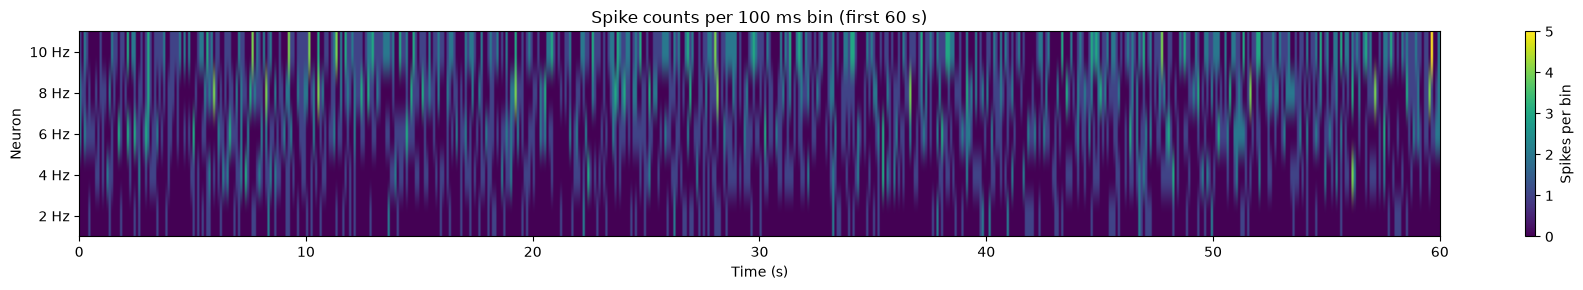

In [148]:
zoom_s = 60 # how many seconds to show; set to 10 for a close-up
zoom_bins = int(round(min(zoom_s, T) / bin_w)) # bins to show, never more than the recording
fig, ax = plt.subplots(figsize=(18, 3)) # one wide plot
im = ax.imshow(counts[:, :zoom_bins], aspect="auto", cmap="viridis", origin="lower", # origin="lower": first neuron at the bottom, same as the raster
               extent=[0, zoom_bins * bin_w, -0.5, len(rates) - 0.5]) # x-axis in seconds, y from bottom row to top row
ax.set_yticks(range(len(rates))) # one y-tick per neuron
ax.set_yticklabels([f"{r} Hz" for r in rates]) # label each row with its rate
ax.set_xlabel("Time (s)")
ax.set_ylabel("Neuron")
ax.set_title(f"Spike counts per {bin_w*1000:.0f} ms bin (first {zoom_bins * bin_w:g} s)")
fig.colorbar(im, ax=ax, label="Spikes per bin") # colour scale
plt.tight_layout() # avoid overlapping labels
plt.show()

## 5. Population rate and bursts

The **population count** is the sum of the counts of all neurons in each bin. Dividing by the bin width gives the population rate (Hz). It shows how active the whole network is at each moment.

For independent Poisson neurons the population count is also Poisson, with mean $\sum_i \lambda_i \cdot \Delta t$ (here (2+4+6+8+10) Hz × 0.1 s = 3 spikes per bin) and variance equal to the mean.

A simple **burst detector** marks bins where the population count exceeds mean + 2 SD. Because our neurons are independent, there are no real bursts: about 3% of bins cross the threshold by chance alone. This is the **"no bursts" baseline**. In real cultures, network bursts (most neurons firing together) push the population far above the threshold.

In [143]:
pop = counts.sum(axis=0) # population count: add all neurons (rows) in each bin (column)
print(f"population shape: {pop.shape} (one value per bin)") # 1 row, n_bins values
print(f"first 15 bins: {pop[:15]}\n") # a peek at the population activity

expected = sum(rates) * bin_w # expected population count per bin (theory)
print(f"expected mean per bin: {expected:.1f} | measured mean: {pop.mean():.2f} | "
      f"variance: {pop.var():.2f} | SD: {pop.std():.2f}") # Poisson: variance ≈ mean

thr = pop.mean() + 2 * pop.std() # burst threshold: mean + 2 SD (from the data, works on real recordings too)
burst = pop > thr # True for each bin above the threshold
print(f"threshold: {thr:.2f} spikes per bin | burst bins: {burst.sum()} of {n_bins} ({100 * burst.mean():.1f}%)")
print(f"highest population count: {pop.max()} spikes in one bin")
print(f"first burst-bin start times (s): {np.round(edges[:-1][burst][:10], 1)}") # edges[:-1] = start time of each bin

population shape: (600,) (one value per bin)
first 15 bins: [5 1 5 2 3 1 1 2 2 2 3 1 2 4 4]

expected mean per bin: 3.0 | measured mean: 3.10 | variance: 3.02 | SD: 1.74
threshold: 6.57 spikes per bin | burst bins: 20 of 600 (3.3%)
highest population count: 9 spikes in one bin
first burst-bin start times (s): [ 2.4  3.   7.1  8.2  9.2 10.5 12.1 14.4 19.2 28. ]


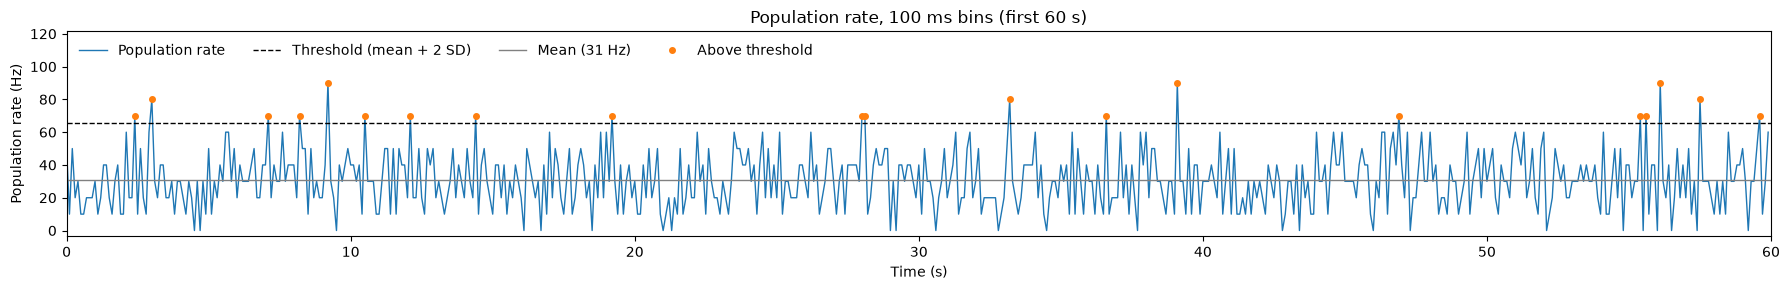

In [ ]:
zoom_s = 60 # how many seconds to show; set to 10 for a close-up
zoom = min(zoom_s, T) # seconds to show, from your settings
zoom_bins = int(round(zoom / bin_w)) # bins to show
t_bins = edges[:-1][:zoom_bins] # start time of each shown bin (s)

fig, ax = plt.subplots(figsize=(18, 3)) # one wide plot
ax.plot(t_bins, pop[:zoom_bins] / bin_w, color="tab:blue", lw=1, label="Population rate") # counts / bin width = rate in Hz
ax.axhline(thr / bin_w, color="black", ls="--", lw=1, label="Threshold (mean + 2 SD)") # burst threshold, also in Hz
ax.axhline(pop.mean() / bin_w, color="gray", lw=1, label=f"Mean ({pop.mean() / bin_w:.0f} Hz)") # average population rate, around which the line zigzags
ax.plot(t_bins[burst[:zoom_bins]], pop[:zoom_bins][burst[:zoom_bins]] / bin_w, "o", # mark the bins above threshold
        color="tab:orange", ms=4, label="Above threshold")
ax.set_xlabel("Time (s)")
ax.set_ylabel("Population rate (Hz)")
ax.set_title(f"Population rate, {bin_w*1000:.0f} ms bins (first {zoom:g} s)")
top = pop.max() / bin_w * 1.35 # top of the y-axis: highest rate + space for the legend
ax.set_xlim(0, zoom) # x-axis starts exactly at 0 and ends at the zoom limit, no empty margin
ax.set_ylim(-0.03 * top, top) # small margin below 0 so dips to 0 Hz aren't cut by the frame
ax.legend(frameon=False, loc="upper left", ncol=4) # legend in one row across the top, above the data
plt.tight_layout() # avoid overlapping labels
plt.show()